<a href="https://colab.research.google.com/github/Zihan-Hei/Histopathology-Thyroid-Cancer-Detection-A-Triple-Class-YOLO26-Approach/blob/main/YOLO26_Thyroid_Histopathology_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 7.3 MB/s eta 0:00:00


In [ ]:
import torch
from ultralytics import YOLO
import os
import zipfile
import yaml
import glob
import shutil
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from collections import Counter
from sklearn.model_selection import train_test_split

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# Data Preparation & Model training on raw data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
project_folder = "/content/drive/MyDrive/Thyroid cancer detectation model training"

print(os.listdir(project_folder))

Mounted at /content/drive
['data_merged.yaml', 'thyroid_merged_run', 'train2(first run)', 'Hyperparameter Tuning', 'thyroid_merged_binary', 'thyroid_merged3classes_run', 'triple_class_validation', 'Thyroid Cancer Detection.v3i.yolo26.zip', 'best_hyperparameters_full.yaml', 'runs', 'thyroid_3class', 'thyroid_3class_aug', 'YOLO26s_3class_tuning']


In [ ]:
zip_path = f"{project_folder}/Thyroid Cancer Detection.v3i.yolo26.zip"

best_yaml_path = f"{project_folder}/best_hyperparameters_full.yaml"

extract_path = "/content/thyroid_dataset"

In [ ]:
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset extracted to:", extract_path)
print(os.listdir(extract_path))

Dataset extracted to: /content/thyroid_dataset
['README.roboflow.txt', 'test', 'valid', 'README.dataset.txt', 'train', 'data.yaml']




---



In [ ]:
# check class imbalance
from collections import Counter
import glob

label_files = glob.glob("/content/thyroid_dataset/train/labels/*.txt")

class_counts = Counter()

for file in label_files:
    with open(file, "r") as f:
        for line in f:
            class_id = int(line.split()[0])
            class_counts[class_id] += 1

print("Class distribution:", class_counts)


Class distribution: Counter({1: 3155, 6: 692, 0: 412, 4: 188, 8: 43, 5: 28, 2: 13, 3: 7, 7: 3})


In [ ]:
import numpy as np

total = sum(class_counts.values())
num_classes = len(class_counts)

class_weights = {}

for cls, count in class_counts.items():
    class_weights[cls] = total / (num_classes * count)

print("Class weights:", class_weights)


Class weights: {1: 0.15992252157069906, 0: 1.2246494066882416, 3: 72.07936507936508, 8: 11.733850129198967, 4: 2.683806146572104, 6: 0.7291265253692999, 5: 18.01984126984127, 7: 168.1851851851852, 2: 38.81196581196581}


In [ ]:
from collections import Counter
import glob
import os
import pandas as pd

base_path = "/content/thyroid_dataset"

if os.path.exists(os.path.join(base_path, "valid")):
    splits = ["train", "valid", "test"]
else:
    splits = ["train", "val", "test"]

distribution = []

for split in splits:

    image_files = (
        glob.glob(f"{base_path}/{split}/images/*.jpg") +
        glob.glob(f"{base_path}/{split}/images/*.jpeg") +
        glob.glob(f"{base_path}/{split}/images/*.png")
    )

    label_files = glob.glob(f"{base_path}/{split}/labels/*.txt")

    class_counts = Counter()

    for file in label_files:
        with open(file, "r") as f:
            for line in f:
                if line.strip():
                    class_id = int(line.split()[0])
                    class_counts[class_id] += 1

    total_objects = sum(class_counts.values())

    for cls, count in sorted(class_counts.items()):
        distribution.append({
            "Split": split,
            "Class": cls,
            "Count": count,
            "Percentage": count / total_objects * 100,
            "Images": len(image_files)
        })

distribution_df = pd.DataFrame(distribution)

print(distribution_df)

    Split  Class  Count  Percentage  Images
0   train      0    412    9.072891     364
1   train      1   3155   69.478089     364
2   train      2     13    0.286281     364
3   train      3      7    0.154151     364
4   train      4    188    4.140057     364
5   train      5     28    0.616604     364
6   train      6    692   15.238934     364
7   train      7      3    0.066065     364
8   train      8     43    0.946928     364
9   valid      0    436   26.092160     117
10  valid      1    899   53.800120     117
11  valid      2      1    0.059844     117
12  valid      3      3    0.179533     117
13  valid      4     59    3.530820     117
14  valid      6    262   15.679234     117
15  valid      7      1    0.059844     117
16  valid      8     10    0.598444     117
17   test      0     27    4.821429      52
18   test      1    375   66.964286      52
19   test      2      1    0.178571      52
20   test      3      1    0.178571      52
21   test      4     22    3.928

Split   test  train  valid
Class                     
0       4.82   9.07  26.09
1      66.96  69.48  53.80
2       0.18   0.29   0.06
3       0.18   0.15   0.18
4       3.93   4.14   3.53
5        NaN   0.62    NaN
6      22.50  15.24  15.68
7       0.36   0.07   0.06
8       1.07   0.95   0.60


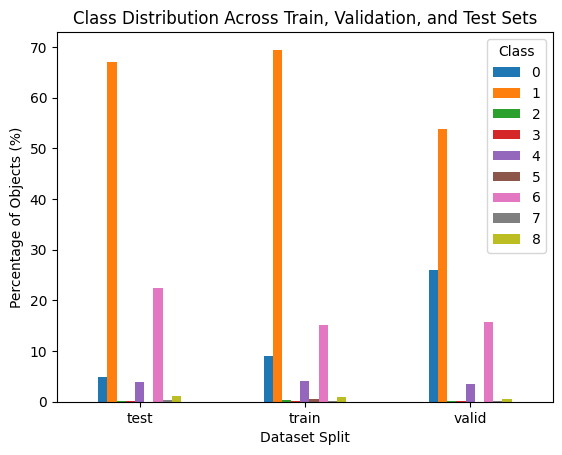

In [ ]:
percentage_table = distribution_df.pivot(
    index="Class",
    columns="Split",
    values="Percentage"
)

print(percentage_table.round(2))

percentage_table.T.plot(kind="bar")

plt.ylabel("Percentage of Objects (%)")
plt.xlabel("Dataset Split")
plt.title("Class Distribution Across Train, Validation, and Test Sets")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

In [ ]:
data_yaml = "/content/thyroid_dataset/data.yaml"

import yaml

with open(data_yaml, "r") as f:
    cfg = yaml.safe_load(f)

print("Classes:", cfg["names"])
print("Number of classes:", len(cfg["names"]))

Classes: ['TC', 'abnormal', 'fibrocollagenous tissue', 'fibromuscular tissue', 'inflammatory cell', 'lymphoid', 'normal', 'rbc', 'stroma']
Number of classes: 9


In [ ]:
# Load a pretrained YOLO26 detection model
model = YOLO("yolo26s.pt")

# Run inference on an image
results = model.train(
    data="/content/thyroid_dataset/data.yaml",
    epochs=150,
    imgsz=640,
    batch=16,
    device=0,

    # Keep validation during training
    val=True,

    # Save permanently to Drive
    project=(
        "/content/drive/MyDrive/"
        "Thyroid cancer detectation model training/runs"
    ),
    name="YOLO26s_9class_raw_baseline",

    plots=True,
    save=True
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thyroid_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO26s_9class_raw_baseline, nbs=64, nms=None, opset=

In [ ]:
from ultralytics import YOLO
import os

run_folder = (
    "/content/drive/MyDrive/"
    "Thyroid cancer detectation model training/"
    "runs/YOLO26s_9class_raw_baseline"
)

best_model_path = f"{run_folder}/weights/best.pt"

print("best.pt exists:", os.path.exists(best_model_path))
print(best_model_path)

best.pt exists: True
/content/drive/MyDrive/Thyroid cancer detectation model training/runs/YOLO26s_9class_raw_baseline/weights/best.pt


In [ ]:
model = YOLO(best_model_path)
data_yaml = "/content/thyroid_dataset/data.yaml"

test_results = model.val(
    data=data_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,

    project=(
        "/content/drive/MyDrive/"
        "Thyroid cancer detectation model training/runs"
    ),
    name="YOLO26s_9class_raw_test"
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,468,663 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 38.4±19.2 MB/s, size: 60.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/thyroid_dataset/test/labels... 52 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 824.4it/s 0.1s
val: New cache created: /content/thyroid_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         52        560       0.57      0.256      0.178     0.0659
                    TC          1         27      0.122      0.889      0.248      0.112
              abnormal         23        375      0.633      0.539      0.566      0.202
fibroco

## Raw Data (9 classes): Apply Hyperparameter Tuning


In [ ]:
# hyperparameter tuning on full data
model = YOLO("yolo26s.pt")

search_space = {
    "lr0":     (1e-5, 3e-3),
    "cls":     (0.25, 2.0),
    "mosaic":  (0.0, 1.0),
    "degrees": (0.0, 45.0),
}

model.tune(
    data="/content/thyroid_dataset/data.yaml",
    epochs=30,
    iterations=20,
    optimizer="AdamW",
    space=search_space,
    imgsz=640,
    plots=True,
    save=False
)

Tuner: Initialized Tuner instance with 'tune_dir=/content/runs/detect/tune-2'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/20 with hyperparameters: {'lr0': 0.003, 'cls': 0.5, 'mosaic': 1.0, 'degrees': 0.0}

MultiTrainer 1/1: fine-tuning on /content/thyroid_dataset/data.yaml
MultiTrainer results saved to /content/runs/detect/multitrain-2/multitrain_results.json
MultiTrainer results saved to /content/runs/detect/multitrain-2/multitrain_results.png
Saved /content/runs/detect/tune-2/tune_scatter_plots.png
Saved /content/runs/detect/tune-2/tune_fitness.png

Tuner: 1/20 iterations complete ✅ (291.33s)
Tuner: Results saved to /content/runs/detect/tune-2
Tuner: Best fitness=0.0601 observed at iteration 1
Tuner: Best fitness metrics are {'metrics/precision(B)': 0.48612, 'metrics/recall(B)': 0.18535, 'metrics/mAP50(B)': 0.15872, 'metrics/mAP50-95(B)': 0.0601, 'val/box_loss': 2.10174, 'val/cls_loss': 2.02681, 'val/l1_loss': 0

In [ ]:
glob.glob("runs/detect/tune*/best_hyperparameters.yaml")

['runs/detect/tune-2/best_hyperparameters.yaml']

In [ ]:
yaml_file = glob.glob(
    "runs/detect/tune*/best_hyperparameters.yaml"
)[-1]

with open(yaml_file, "r") as f:
    best_params = yaml.safe_load(f)

best_params

{'lr0': 0.00286, 'cls': 0.5, 'mosaic': 0.38161, 'degrees': 0.0}

In [ ]:
# With hyperparameter tuning on raw data
model = YOLO("yolo26s.pt")

results = model.train(
    data=f"{extract_path}/data.yaml",

    epochs=150,
    patience=30,
    imgsz=640,
    batch=16,

    optimizer="AdamW",

    lr0=best_params["lr0"],
    cls=best_params["cls"],
    mosaic=best_params["mosaic"],
    degrees=best_params["degrees"],

    project=f"{project_folder}/runs",
    name="YOLO26s_tuned_baseline",

    save=True,
    save_period=10,
    plots=True
)

Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thyroid_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00286, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.38161, multi_scale=0.0, name=YOLO26s_tuned_baseline, nbs=64, nm

In [ ]:
# Testing on hyperparameter tuned raw data
best_model = YOLO(
    "/content/drive/MyDrive/Thyroid cancer detectation model training/"
    "runs/YOLO26s_tuned_baseline/weights/best.pt"
)

test_results = best_model.val(
    data="/content/thyroid_dataset/data.yaml",
    split="test",
    plots=True,

    project="/content/drive/MyDrive/Thyroid cancer detectation model training/runs",
    name="YOLO26s_9class_test"
)

Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,468,663 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1415.9±331.8 MB/s, size: 61.3 KB)
val: Scanning /content/thyroid_dataset/test/labels.cache... 52 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 12.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.2s
                   all         52        560      0.726      0.249      0.203     0.0794
                    TC          1         27      0.145      0.889      0.334      0.155
              abnormal         23        375      0.638       0.53      0.565      0.211
fibrocollagenous tissue          1          1          1          0          0          0
  fibromuscular tissue          1          1          1          0     0.0037    0.00074
     inflammatory cell          4        



---



# Triple-Class: Only keep TC/Abnormal/Normal classes, otherclasses are droped

In [ ]:
!cp -r /content/thyroid_dataset /content/thyroid_dataset_backup
print("Backup saved to /content/thyroid_dataset_backup")

Backup saved to /content/thyroid_dataset_backup


In [ ]:
# Confirm Class Names from data.yaml
with open("/content/thyroid_dataset/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Original classes:")
for i, name in enumerate(data['names']):
    print(f"  {i}: {name}  ({class_counts.get(i, 0)} samples)")

Original classes:
  0: TC  (27 samples)
  1: abnormal  (375 samples)
  2: fibrocollagenous tissue  (1 samples)
  3: fibromuscular tissue  (1 samples)
  4: inflammatory cell  (22 samples)
  5: lymphoid  (0 samples)
  6: normal  (126 samples)
  7: rbc  (2 samples)
  8: stroma  (6 samples)


In [ ]:
# Pool ALL splits into one place first
pool_images = "/content/pool/images"
pool_labels = "/content/pool/labels"
os.makedirs(pool_images, exist_ok=True)
os.makedirs(pool_labels, exist_ok=True)

for split in ['train', 'valid', 'test']:
    for img in glob.glob(
        f"/content/thyroid_dataset/{split}/images/*.jpg"
    ):
        shutil.copy(img, pool_images)
    for lbl in glob.glob(
        f"/content/thyroid_dataset/{split}/labels/*.txt"
    ):
        shutil.copy(lbl, pool_labels)

print(f"Pooled images: {len(os.listdir(pool_images))}")
print(f"Pooled labels: {len(os.listdir(pool_labels))}")

Pooled images: 533
Pooled labels: 533


In [ ]:
# Filter and Remap Labels

classes_to_keep = {
    0: 0,   # TC
    1: 1,   # abnormal
    6: 2,   # normal
}

new_class_names = ['TC', 'abnormal', 'normal']

data = []
skipped_lines = 0
kept_lines = 0
empty_files = 0

filtered_label_folder = "/content/filtered_labels"
os.makedirs(filtered_label_folder, exist_ok=True)

label_files = [f for f in os.listdir(pool_labels) if f.endswith('.txt')]

for file in label_files:
    file_path     = os.path.join(pool_labels, file)
    new_file_path = os.path.join(filtered_label_folder, file)

    with open(file_path, 'r') as f:
        lines_to_keep = []
        for line in f:
            elements = line.strip().split()

            # YOLO format check
            if len(elements) != 5:
                skipped_lines += 1
                print(f"  Malformed line in {file}: {line.strip()}")
                continue

            cls_id = int(elements[0])

            if cls_id not in classes_to_keep:
                continue  # drop ambiguous classes

            try:
                x, y, w, h = map(float, elements[1:])

                # Validate bbox values
                if not all(0.0 <= v <= 1.0 for v in [x, y, w, h]):
                    print(f"  Invalid bbox in {file}: {elements}")
                    skipped_lines += 1
                    continue

                new_id = classes_to_keep[cls_id]
                lines_to_keep.append(f"{new_id} {x} {y} {w} {h}\n")
                data.append([file, new_id, x, y, w, h])
                kept_lines += 1

            except ValueError as e:
                print(f"  Error in {file}: {e}")
                skipped_lines += 1

    if lines_to_keep:
        with open(new_file_path, 'w') as f_out:
            f_out.writelines(lines_to_keep)
    else:
        empty_files += 1

print(f"\nFilter Summary:")
print(f"  Kept lines:    {kept_lines}")
print(f"  Skipped lines: {skipped_lines}")
print(f"  Empty files:   {empty_files} (no TC/abnormal/normal — excluded)")
print(f"  Output labels: {len(os.listdir(filtered_label_folder))}")

  Malformed line in IMG_7449_jpg.rf.4a122e02617e3a9ed18be9bf27214353.txt: 0 0 0 0 1 1 1 1 0 0 0

Filter Summary:
  Kept lines:    6383
  Skipped lines: 1
  Empty files:   135 (no TC/abnormal/normal — excluded)
  Output labels: 398



Class distribution (instances):
class_id
1    69.387435
2    16.919944
0    13.692621
Name: count, dtype: float64


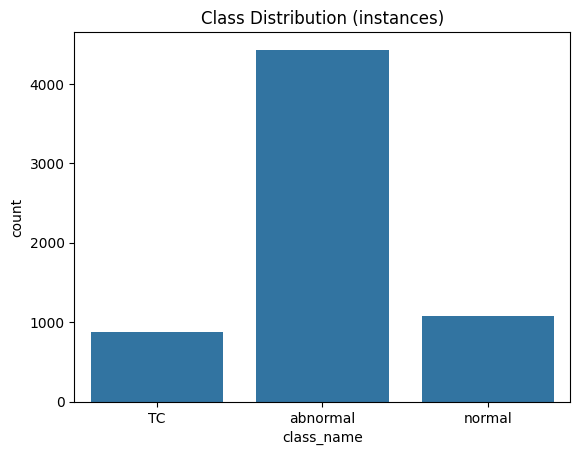

In [ ]:
# Class Distribution + Plot
columns = ['file', 'class_id', 'x_center', 'y_center', 'width', 'height']
df1 = pd.DataFrame(data, columns=columns)

print("\nClass distribution (instances):")
print((df1['class_id'].value_counts() / df1.shape[0]) * 100)

name_map = {0: 'TC', 1: 'abnormal', 2: 'normal'}
df1['class_name'] = df1['class_id'].map(name_map)

sns.countplot(x='class_name', data=df1,
              order=['TC', 'abnormal', 'normal'])
plt.title("Class Distribution (instances)")
plt.show()

In [ ]:
# Build Unique Image List + Stratified Split

# One row per unique image — dominant class for stratification
df1['file_jpg'] = df1['file'].str.replace('.txt', '.jpg')
df_unique = (
    df1.groupby('file_jpg')['class_id']
    .agg(lambda x: x.mode()[0])
    .reset_index()
    .rename(columns={'class_id': 'dominant_class'})
)

print(f"Unique images available: {len(df_unique)}")
print("\nImage count per dominant class:")
for cls_id, count in df_unique['dominant_class'].value_counts().items():
    print(f"  {cls_id} ({new_class_names[cls_id]}): {count} images")

# Stratified 70 / 15 / 15 split
train_df, temp_df = train_test_split(
    df_unique, test_size=0.3, random_state=42,
    stratify=df_unique['dominant_class']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42,
    stratify=temp_df['dominant_class']
)

print(f"\nSplit sizes:")
print(f"  Train: {len(train_df)} images")
print(f"  Val:   {len(val_df)} images")
print(f"  Test:  {len(test_df)} images")


Unique images available: 398

Image count per dominant class:
  1 (abnormal): 270 images
  2 (normal): 98 images
  0 (TC): 30 images

Split sizes:
  Train: 278 images
  Val:   60 images
  Test:  60 images


In [ ]:
# Copy Files into Final Dataset Folder
base_folder = "/content/thyroid_3class"

for split in ['train', 'val', 'test']:
    os.makedirs(f"{base_folder}/{split}/images", exist_ok=True)
    os.makedirs(f"{base_folder}/{split}/labels", exist_ok=True)

def copy_split(df, split):
    copied  = 0
    skipped = 0
    for img_file in df['file_jpg']:
        label_file = img_file.replace('.jpg', '.txt')
        img_src    = os.path.join(pool_images, img_file)
        label_src  = os.path.join(filtered_label_folder, label_file)

        if not os.path.exists(img_src) or \
           not os.path.exists(label_src):
            skipped += 1
            continue

        shutil.copy(img_src,
            f"{base_folder}/{split}/images/{img_file}")
        shutil.copy(label_src,
            f"{base_folder}/{split}/labels/{label_file}")
        copied += 1

    print(f"  {split}: {copied} copied, {skipped} skipped")

print("Copying files:")
copy_split(train_df, 'train')
copy_split(val_df,   'val')
copy_split(test_df,  'test')

# Save data.yaml
data_yaml_content = {
    'train': f'{base_folder}/train/images',
    'val':   f'{base_folder}/val/images',
    'test':  f'{base_folder}/test/images',
    'nc':    3,
    'names': new_class_names,
}

with open(f"{base_folder}/data.yaml", 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print("Saved data.yaml:")
print(f"  Classes: {new_class_names}")
print(f"  nc: 3")

Copying files:
  train: 278 copied, 0 skipped
  val: 60 copied, 0 skipped
  test: 60 copied, 0 skipped
Saved data.yaml:
  Classes: ['TC', 'abnormal', 'normal']
  nc: 3


In [ ]:
import yaml
import os

data_yaml = (
    "/content/drive/MyDrive/"
    "Thyroid cancer detectation model training/"
    "thyroid_3class/data.yaml"
)
print("Exists:", os.path.exists(data_yaml))

with open(data_yaml, "r") as f:
    cfg = yaml.safe_load(f)

print(cfg)

Exists: True
{'path': '/content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'names': {0: 'TC', 1: 'abnormal', 2: 'normal'}}


## Triple-Class Raw Training & Testing

In [ ]:
# 3-classes raw training
model = YOLO("yolo26s.pt")

results = model.train(
    data=data_yaml,
    epochs=100,
    patience=0,
    imgsz=640,
    batch=16,
    device=0,
    project=(
        "/content/drive/MyDrive/"
        "Thyroid cancer detectation model training/runs"
    ),
    name="YOLO26s_3class_raw_baseline",

    save=True,
    plots=True
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [ ]:
run_folder = (
    "/content/drive/MyDrive/"
    "Thyroid cancer detectation model training/"
    "runs/YOLO26s_3class_raw_baseline"
)

best_model_path = f"{run_folder}/weights/best.pt"

print("best.pt exists:", os.path.exists(best_model_path))
print(best_model_path)

best.pt exists: True
/content/drive/MyDrive/Thyroid cancer detectation model training/runs/YOLO26s_3class_raw_baseline/weights/best.pt


In [ ]:
# 3-classes raw testing
raw_model = YOLO(best_model_path)
data_yaml = (
    "/content/drive/MyDrive/"
    "Thyroid cancer detectation model training/"
    "thyroid_3class/data.yaml"
)
raw_test_results = raw_model.val(
    data=data_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,

    project=(
        "/content/drive/MyDrive/"
        "Thyroid cancer detectation model training/runs"
    ),
    name="YOLO26s_3class_raw_test"
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.4 ms, read: 20.6±31.1 MB/s, size: 59.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class/test/labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.9it/s 32.1s
val: New cache created: /content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1s/it 4.3s
                   all         60        933      0.436      0.542      0.456      0.162
                    TC          4        112      0.361      0.278      0.28

## Triple-Class: Apply Data Augmentation and Hyperparameter Tuning

In [ ]:
# Data Augmentation (3-class: TC / Abnormal / Normal)
# Generates horizontally-flipped, vertically-flipped, and 90°-rotated copies
# of every training image+label. Val/test are left untouched.
# Augmented files are written back into thyroid_3class/train/.

from PIL import Image
import cv2, os, glob

aug_train_img = f"{base_folder}/train/images"
aug_train_lbl = f"{base_folder}/train/labels"

def read_labels(path):
    rows = []
    with open(path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                rows.append([int(parts[0])] + [float(v) for v in parts[1:]])
    return rows

def write_labels(path, rows):
    with open(path, 'w') as f:
        for r in rows:
            f.write(f"{r[0]} {r[1]:.6f} {r[2]:.6f} {r[3]:.6f} {r[4]:.6f}\n")

def flip_horizontal(rows):
    return [[r[0], 1.0-r[1], r[2], r[3], r[4]] for r in rows]

def flip_vertical(rows):
    return [[r[0], r[1], 1.0-r[2], r[3], r[4]] for r in rows]

def rotate_90(rows):
    return [[r[0], 1.0-r[2], r[1], r[4], r[3]] for r in rows]

augmentations = [
    ('hflip', lambda img: cv2.flip(img, 1),  flip_horizontal),
    ('vflip',  lambda img: cv2.flip(img, 0),  flip_vertical),
    ('rot90',  lambda img: cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE), rotate_90),
]

# minority classes only (TC=0, abnormal=1 for binary; adjust for 3-class)
MINORITY_CLASSES = {0, 2}  # TC and normal

orig_images = [f for f in glob.glob(f"{aug_train_img}/*.jpg")
               if '_hflip' not in f and '_vflip' not in f and '_rot90' not in f]

aug_count = 0
skipped = 0

for img_path in orig_images:
    stem     = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(aug_train_lbl, stem + '.txt')
    if not os.path.exists(lbl_path):
        continue

    rows = read_labels(lbl_path)
    class_ids = {r[0] for r in rows}

    if not class_ids.intersection(MINORITY_CLASSES):
        skipped += 1
        continue  # skip abnormal-only images

    img = cv2.imread(img_path)
    for suffix, img_fn, lbl_fn in augmentations:
        aug_img  = img_fn(img)
        aug_rows = lbl_fn(rows)
        cv2.imwrite(os.path.join(aug_train_img, f"{stem}_{suffix}.jpg"), aug_img)
        write_labels(os.path.join(aug_train_lbl, f"{stem}_{suffix}.txt"), aug_rows)
        aug_count += 1

print(f"Augmented {aug_count} files, skipped {skipped} abnormal-only images")


Augmented 267 files, skipped 189 abnormal-only images


In [ ]:
from collections import Counter
import glob

counts = Counter()
for lbl in glob.glob(f"{base_folder}/train/labels/*.txt"):
    with open(lbl) as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                counts[int(parts[0])] += 1
print("Class distribution after augmentation:", counts)

Class distribution after augmentation: Counter({1: 3190, 2: 2984, 0: 2456})


In [ ]:
# Hyperparameter Tuning
np.random.seed(42)
lr0_center = 10 ** np.random.uniform(-5, -2)
lr0_low    = max(1e-5, lr0_center / 3)
lr0_high   = min(1e-2, lr0_center * 3)

print(f"Log-sampled lr0 center: {lr0_center:.6f}")
print(f"lr0 search range: ({lr0_low:.6f}, {lr0_high:.6f})")

model = YOLO("yolo26s.pt")

search_space = {
    "lr0":     (lr0_low, lr0_high),
    "cls":     (0.5, 4.0),
    "mosaic":  (0.5, 1.0),
    "degrees": (0.0, 180.0),
}

model.tune(
    data=f"{base_folder}/data.yaml",
    epochs=5,
    iterations=20,
    optimizer="AdamW",
    space=search_space,
    plots=False,
    save=False,
    val=False,
    imgsz=416,
    batch=16,
    device=0,
)

print("Tuning complete")


Log-sampled lr0 center: 0.000133
lr0 search range: (0.000044, 0.000399)
Tuner: Initialized Tuner instance with 'tune_dir=/content/runs/detect/tune'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/20 with hyperparameters: {'lr0': 0.0004, 'cls': 0.5, 'mosaic': 1.0, 'degrees': 0.0}


KeyboardInterrupt: 

In [ ]:
# Load Best Hyperparameters
tune_folders = sorted(glob.glob("/content/runs/detect/tune*"))
latest_tune  = tune_folders[-1]
best_hp_path = f"{latest_tune}/best_hyperparameters.yaml"

with open(best_hp_path, "r") as f:
    best_hps = yaml.safe_load(f)

print(f"Loaded from: {best_hp_path}")
print("Best hyperparameters:")
for k, v in best_hps.items():
    print(f"  {k}: {v}")


Loaded from: /content/runs/detect/tune/best_hyperparameters.yaml
Best hyperparameters:
  lr0: 0.0004
  cls: 0.60969
  mosaic: 0.59377
  degrees: 0.00882


In [ ]:
# Full Training on triple-class
model = YOLO("yolo26s.pt")

model.train(
    data=f"{base_folder}/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    optimizer="AdamW",
    cos_lr=True,
    patience=0,
    # Tuned hyperparameters
    lr0=0.0001,
    lrf=0.01,
    warmup_epochs=10,
    mosaic=0.59377,
    degrees=0.0,
    # needs more weight given 3class imbalance
    cls=3.0,
    box=7.5,
    # Augmentations
    flipud=0.5,
    fliplr=0.5,
    hsv_h=0.01,
    hsv_s=0.5,
    hsv_v=0.3,
    copy_paste=0.0,
    label_smoothing=0.1,
)

In [ ]:
# Save to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# save merged train sets
!cp -r /content/runs/detect/train7 /content/drive/MyDrive/thyroid_merged3classes_run

# Verify what's in train
!ls /content/runs/detect/train7
!ls /content/runs/detect/train7/weights

Mounted at /content/drive
args.yaml			 labels.jpg	      train_batch1.jpg
BoxF1_curve.png			 results.csv	      train_batch2.jpg
BoxP_curve.png			 results.png	      val_batch0_labels.jpg
BoxPR_curve.png			 train_batch0.jpg     val_batch0_pred.jpg
BoxR_curve.png			 train_batch1620.jpg  val_batch1_labels.jpg
confusion_matrix_normalized.png  train_batch1621.jpg  val_batch1_pred.jpg
confusion_matrix.png		 train_batch1622.jpg  weights
best.pt  last.pt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import glob
import os

run_folder = "/content/drive/MyDrive/thyroid_merged3classes_run"

best_models = glob.glob(
    f"{run_folder}/**/best.pt",
    recursive=True
)

print("Found models:")
for p in best_models:
    print(p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found models:


In [ ]:
model_path = "/content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_merged3classes_run/weights/best.pt"

from ultralytics import YOLO

model = YOLO(model_path)

data_yaml = (
    "/content/drive/MyDrive/"
    "Thyroid cancer detectation model training/"
    "thyroid_3class_aug/data.yaml"
)

In [ ]:
# Full Testing on triple-class
test_results = model.val(
    data=data_yaml,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,

    project="/content/drive/MyDrive",
    name="thyroid_merged3classes_test"
)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.2 ms, read: 0.1±0.1 MB/s, size: 63.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class_aug/test/labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.1it/s 53.7s
val: New cache created: /content/drive/MyDrive/Thyroid cancer detectation model training/thyroid_3class_aug/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2s/it 5.0s
                   all         60        933      0.541      0.606      0.571      0.225
                    TC          4        112      0.413      0.357    



---



# **Appendix**
## Below including the process of merge imbalanced classes, training on Binary Classes (TC/Normal), and used the approach of Mixed Scene.



---



# Merge Imbalanced Classes

In [ ]:
# Confirm Class Names from data.yaml
with open("/content/thyroid_dataset/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Original classes:")
for i, name in enumerate(data['names']):
    print(f"  {i}: {name}  ({class_counts.get(i, 0)} samples)")

Original classes:
  0: TC  (412 samples)
  1: abnormal  (3155 samples)
  2: fibrocollagenous tissue  (13 samples)
  3: fibromuscular tissue  (7 samples)
  4: inflammatory cell  (188 samples)
  5: lymphoid  (28 samples)
  6: normal  (692 samples)
  7: rbc  (3 samples)
  8: stroma  (43 samples)


In [ ]:
# Backup Dataset Before Modifying Labels
!cp -r /content/thyroid_dataset /content/thyroid_dataset_backup
print("Backup saved to /content/thyroid_dataset_backup")

Backup saved to /content/thyroid_dataset_backup


In [ ]:
# Define Merge Strategy

# 0=TC, 1=abnormal, 2=fibrocollagenous tissue, 3=fibromuscular tissue,
# 4=inflammatory cell, 5=lymphoid, 6=normal, 7=rbc, 8=stroma

# Merges:
# fibrocollagenous (2)   - stroma: shared connective tissue origin
# fibromuscular (3)    - stroma: shared connective tissue origin
# rbc (7)              - normal: background vascularity, non-diagnostic
# stroma (8)           - stroma: kept as base class
# lymphoid (5)         - inflammatory cell: lymphoid infiltration is a type of inflammatory response

merge_map = {
    0: 0,   # TC - TC
    1: 1,   # abnormal - abnormal
    2: 2,   # fibrocollagenous - stroma
    3: 2,   # fibromuscular - stroma
    4: 3,   # inflammatory cell - inflammatory cell
    5: 3,   # lymphoid - inflammatory cell (lymphoid is inflammatory)
    6: 4,   # normal - normal
    7: 4,   # rbc - normal
    8: 2,   # stroma - stroma
}

new_class_names = [
    "TC",                 # 0
    "abnormal",              # 1
    "stroma",               # 2 (merged: fibrocollagenous + fibromuscular + stroma)
    "inflammatory cell",         # 3 (merged: inflammatory cell + lymphoid)
    "normal",               # 4 (merged: normal + rbc)
]

print("Merge map:", merge_map)
print("New classes:", new_class_names)

Merge map: {0: 0, 1: 1, 2: 2, 3: 2, 4: 3, 5: 3, 6: 4, 7: 4, 8: 2}
New classes: ['TC', 'abnormal', 'stroma', 'inflammatory cell', 'normal']


In [ ]:
# Apply Merge to Label Files
def merge_labels(label_dir, merge_map):
    files = glob.glob(f"{label_dir}/*.txt")
    dropped = 0
    kept = 0

    for fpath in files:
        with open(fpath, "r") as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            cls_id = int(parts[0])

            if cls_id not in merge_map:
                dropped += 1
                print(f"  WARNING: unexpected class id {cls_id} in {fpath}")
                continue  # drop any unmapped class

            new_id = merge_map[cls_id]
            new_lines.append(f"{new_id} " + " ".join(parts[1:]) + "\n")
            kept += 1

        with open(fpath, "w") as f:
            f.writelines(new_lines)

    print(f"{label_dir}: kept {kept}, dropped {dropped} annotations")

merge_labels("/content/thyroid_dataset/train/labels", merge_map)
merge_labels("/content/thyroid_dataset/valid/labels", merge_map)
merge_labels("/content/thyroid_dataset/test/labels",  merge_map)

/content/thyroid_dataset/train/labels: kept 4541, dropped 0 annotations
/content/thyroid_dataset/valid/labels: kept 1671, dropped 0 annotations
/content/thyroid_dataset/test/labels: kept 560, dropped 0 annotations


In [ ]:
# Save Updated data.yaml
data_merged = data.copy()
data_merged['nc'] = len(new_class_names)
data_merged['names'] = new_class_names

with open("/content/thyroid_dataset/data_merged.yaml", "w") as f:
    yaml.dump(data_merged, f)

print("Saved data_merged.yaml")
print("Classes:", new_class_names)
print("Number of classes:", len(new_class_names))

Saved data_merged.yaml
Classes: ['TC', 'abnormal', 'stroma', 'inflammatory cell', 'normal']
Number of classes: 5


In [ ]:
# Verify New Class Distribution
label_files = glob.glob("/content/thyroid_dataset/train/labels/*.txt")
new_class_counts = Counter()

for file in label_files:
    with open(file, "r") as f:
        for line in f:
            class_id = int(line.split()[0])
            new_class_counts[class_id] += 1

print("New class distribution after merging:")
for i, name in enumerate(new_class_names):
    print(f"  {i} ({name}): {new_class_counts.get(i, 0)} samples")

New class distribution after merging:
  0 (TC): 412 samples
  1 (abnormal): 3155 samples
  2 (stroma): 63 samples
  3 (inflammatory cell): 216 samples
  4 (normal): 695 samples


In [ ]:
# Train on Merged Dataset
model = YOLO("yolo26s.pt")

model.train(
    data="/content/thyroid_dataset/data_merged.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    optimizer="AdamW",
    cos_lr=True,
    patience=50,
    # From hyperparameter tuning
    lr0=0.00088,
    mosaic=0.89,
    # Adjusted for 5-class problem
    cls=1.5,
    box=7.5,
    dfl=1.5,
    copy_paste=0.3,
    flipud=0.5,
    fliplr=0.5,
    hsv_s=0.7,
    hsv_v=0.4,
    label_smoothing=0.1,
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=1.5, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/thyroid_dataset/data_merged.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00088, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.89, multi_scale=0.0, name=train2, nbs=64, nms=Fal

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78b1c05f2270>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [ ]:
# Validate Best Model
model = YOLO("/content/runs/detect/train2/weights/best.pt")

model.val(
    data="/content/thyroid_dataset/data_merged.yaml",
    conf=0.1,
    iou=0.5,
    save_json=True,
    plots=True,
)

Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,467,115 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1555.3±463.1 MB/s, size: 59.9 KB)
val: Scanning /content/thyroid_dataset/valid/labels.cache... 117 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 117/117 30.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8it/s 4.5s
                   all        117       1671      0.264      0.344      0.281      0.115
                    TC         15        436      0.319      0.298      0.261      0.108
              abnormal         56        899      0.449      0.617      0.551      0.242
                stroma         14         14          0          0          0          0
     inflammatory cell          9         59      0.158      0.271      0.161     0.0517
                normal         23      

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78b1c06548c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [ ]:
# Save to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# save merged train sets
!cp -r /content/runs/detect/train2 /content/drive/MyDrive/thyroid_merged_run

# Verify what's in train2
!ls /content/runs/detect/train2
!ls /content/runs/detect/train2/weights

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2070.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch2071.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch2072.jpg  weights
labels.jpg			 train_batch2.jpg
best.pt  last.pt


# Binary Classes traning (TC/Normal)

In [ ]:
!cp -r /content/thyroid_dataset /content/thyroid_dataset_backup
print("Backup saved to /content/thyroid_dataset_backup")

Backup saved to /content/thyroid_dataset_backup


In [ ]:
# Confirm Class Names from data.yaml
with open("/content/thyroid_dataset/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Original classes:")
for i, name in enumerate(data['names']):
    print(f"  {i}: {name}  ({class_counts.get(i, 0)} samples)")

Original classes:
  0: TC  (412 samples)
  1: abnormal  (3155 samples)
  2: fibrocollagenous tissue  (13 samples)
  3: fibromuscular tissue  (7 samples)
  4: inflammatory cell  (188 samples)
  5: lymphoid  (28 samples)
  6: normal  (692 samples)
  7: rbc  (3 samples)
  8: stroma  (43 samples)


In [ ]:
# Pool ALL splits into one place first
pool_images = "/content/pool/images"
pool_labels = "/content/pool/labels"
os.makedirs(pool_images, exist_ok=True)
os.makedirs(pool_labels, exist_ok=True)

for split in ['train', 'valid', 'test']:
    for img in glob.glob(
        f"/content/thyroid_dataset/{split}/images/*.jpg"
    ):
        shutil.copy(img, pool_images)
    for lbl in glob.glob(
        f"/content/thyroid_dataset/{split}/labels/*.txt"
    ):
        shutil.copy(lbl, pool_labels)

print(f"Pooled images: {len(os.listdir(pool_images))}")
print(f"Pooled labels: {len(os.listdir(pool_labels))}")

Pooled images: 533
Pooled labels: 533


In [ ]:
# Filter and Remap Labels

classes_to_keep = {
    0: 0,   # TC
    6: 1,   # normal
}

new_class_names = ['TC','normal']

data = []
skipped_lines = 0
kept_lines = 0
empty_files = 0

filtered_label_folder = "/content/filtered_labels"
os.makedirs(filtered_label_folder, exist_ok=True)

label_files = [f for f in os.listdir(pool_labels) if f.endswith('.txt')]

for file in label_files:
    file_path     = os.path.join(pool_labels, file)
    new_file_path = os.path.join(filtered_label_folder, file)

    with open(file_path, 'r') as f:
        lines_to_keep = []
        for line in f:
            elements = line.strip().split()

            # YOLO format check
            if len(elements) != 5:
                skipped_lines += 1
                print(f"  Malformed line in {file}: {line.strip()}")
                continue

            cls_id = int(elements[0])

            if cls_id not in classes_to_keep:
                continue  # drop ambiguous classes

            try:
                x, y, w, h = map(float, elements[1:])

                # Validate bbox values
                if not all(0.0 <= v <= 1.0 for v in [x, y, w, h]):
                    print(f"  Invalid bbox in {file}: {elements}")
                    skipped_lines += 1
                    continue

                new_id = classes_to_keep[cls_id]
                lines_to_keep.append(f"{new_id} {x} {y} {w} {h}\n")
                data.append([file, new_id, x, y, w, h])
                kept_lines += 1

            except ValueError as e:
                print(f"  Error in {file}: {e}")
                skipped_lines += 1

    if lines_to_keep:
        with open(new_file_path, 'w') as f_out:
            f_out.writelines(lines_to_keep)
    else:
        empty_files += 1

print(f"Filter Summary:")
print(f"  Kept lines:    {kept_lines}")
print(f"  Skipped lines: {skipped_lines}")
print(f"  Empty files:   {empty_files} (no TC/normal — excluded)")
print(f"  Output labels: {len(os.listdir(filtered_label_folder))}")

  Malformed line in IMG_7449_jpg.rf.4a122e02617e3a9ed18be9bf27214353.txt: 0 0 0 0 1 1 1 1 0 0 0

Filter Summary:
  Kept lines:    1954
  Skipped lines: 1
  Empty files:   405 (no TC/normal — excluded)
  Output labels: 128



Class distribution (instances):
class_id
1    55.271238
0    44.728762
Name: count, dtype: float64


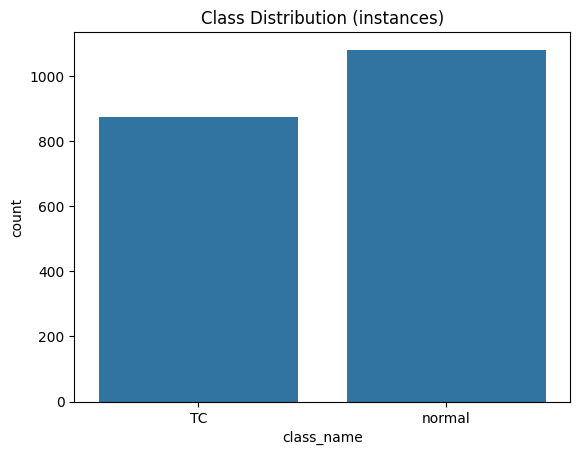

In [ ]:
# Class Distribution + Plot
columns = ['file', 'class_id', 'x_center', 'y_center', 'width', 'height']
df1 = pd.DataFrame(data, columns=columns)

print("\nClass distribution (instances):")
print((df1['class_id'].value_counts() / df1.shape[0]) * 100)

name_map = {0: 'TC', 1: 'normal'}
df1['class_name'] = df1['class_id'].map(name_map)

sns.countplot(x='class_name', data=df1,
              order=['TC', 'normal'])
plt.title("Class Distribution (instances)")
plt.show()

In [ ]:
# Build Unique Image List + Stratified Split

# One row per unique image — dominant class for stratification
df1['file_jpg'] = df1['file'].str.replace('.txt', '.jpg')
df_unique = (
    df1.groupby('file_jpg')['class_id']
    .agg(lambda x: x.mode()[0])
    .reset_index()
    .rename(columns={'class_id': 'dominant_class'})
)

print(f"Unique images available: {len(df_unique)}")
print("\nImage count per dominant class:")
for cls_id, count in df_unique['dominant_class'].value_counts().items():
    print(f"  {cls_id} ({new_class_names[cls_id]}): {count} images")

# Stratified 70 / 15 / 15 split
train_df, temp_df = train_test_split(
    df_unique, test_size=0.3, random_state=42,
    stratify=df_unique['dominant_class']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42,
    stratify=temp_df['dominant_class']
)

print(f"Split sizes:")
print(f"  Train: {len(train_df)} images")
print(f"  Val:   {len(val_df)} images")
print(f"  Test:  {len(test_df)} images")


Unique images available: 128

Image count per dominant class:
  1 (normal): 98 images
  0 (TC): 30 images

Split sizes:
  Train: 89 images
  Val:   19 images
  Test:  20 images


In [ ]:
# Copy Files into Final Dataset Folder
base_folder = "/content/thyroid_binary_class"

for split in ['train', 'val', 'test']:
    os.makedirs(f"{base_folder}/{split}/images", exist_ok=True)
    os.makedirs(f"{base_folder}/{split}/labels", exist_ok=True)

def copy_split(df, split):
    copied  = 0
    skipped = 0
    for img_file in df['file_jpg']:
        label_file = img_file.replace('.jpg', '.txt')
        img_src    = os.path.join(pool_images, img_file)
        label_src  = os.path.join(filtered_label_folder, label_file)

        if not os.path.exists(img_src) or \
           not os.path.exists(label_src):
            skipped += 1
            continue

        shutil.copy(img_src,
            f"{base_folder}/{split}/images/{img_file}")
        shutil.copy(label_src,
            f"{base_folder}/{split}/labels/{label_file}")
        copied += 1

    print(f"  {split}: {copied} copied, {skipped} skipped")

print("Copying files:")
copy_split(train_df, 'train')
copy_split(val_df,   'val')
copy_split(test_df,  'test')

# Save data.yaml
data_yaml_content = {
    'train': f'{base_folder}/train/images',
    'val':   f'{base_folder}/val/images',
    'test':  f'{base_folder}/test/images',
    'nc':    2,
    'names': new_class_names,
}

with open(f"{base_folder}/data.yaml", 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print("Saved data.yaml:")
print(f"  Classes: {new_class_names}")
print(f"  nc: 2")

Copying files:
  train: 89 copied, 0 skipped
  val: 19 copied, 0 skipped
  test: 20 copied, 0 skipped
Saved data.yaml:
  Classes: ['TC', 'normal']
  nc: 2


In [ ]:
# Data Augmentation (Binary: TC / Normal)
# Generates horizontally flipped, vertically flipped, and 90 degree rotated copies of every training image+label. Val/test are left untouched.
# Augmented files are written back into thyroid_binary_class/train/.

import cv2
import numpy as np
import os, glob

aug_train_img = f"{base_folder}/train/images"
aug_train_lbl = f"{base_folder}/train/labels"

def read_labels(path):
    rows = []
    with open(path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                rows.append([int(parts[0])] + [float(v) for v in parts[1:]])
    return rows

def write_labels(path, rows):
    with open(path, 'w') as f:
        for r in rows:
            f.write(f"{r[0]} {r[1]:.6f} {r[2]:.6f} {r[3]:.6f} {r[4]:.6f}\n")

def flip_horizontal(rows):
    """Mirror left↔right: x_center → 1 - x_center, y/w/h unchanged."""
    return [[r[0], 1.0 - r[1], r[2], r[3], r[4]] for r in rows]

def flip_vertical(rows):
    """Mirror top↔bottom: y_center → 1 - y_center, x/w/h unchanged."""
    return [[r[0], r[1], 1.0 - r[2], r[3], r[4]] for r in rows]

def rotate_90(rows):
    """Rotate 90° CW: (x,y,w,h) → (1-y, x, h, w)."""
    return [[r[0], 1.0 - r[2], r[1], r[4], r[3]] for r in rows]

augmentations = [
    ('hflip',  lambda img: cv2.flip(img, 1),  flip_horizontal),
    ('vflip',  lambda img: cv2.flip(img, 0),  flip_vertical),
    ('rot90',  lambda img: cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE), rotate_90),
]

orig_images = glob.glob(f"{aug_train_img}/*.jpg")
aug_count = 0

for img_path in orig_images:
    stem      = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path  = os.path.join(aug_train_lbl, stem + '.txt')
    if not os.path.exists(lbl_path):
        continue

    img  = cv2.imread(img_path)
    rows = read_labels(lbl_path)

    for suffix, img_fn, lbl_fn in augmentations:
        aug_img  = img_fn(img)
        aug_rows = lbl_fn(rows)
        out_img  = os.path.join(aug_train_img, f"{stem}_{suffix}.jpg")
        out_lbl  = os.path.join(aug_train_lbl, f"{stem}_{suffix}.txt")
        cv2.imwrite(out_img, aug_img)
        write_labels(out_lbl, aug_rows)
        aug_count += 1

print(f"Binary section — augmentation complete.")
print(f"  Original training images : {len(orig_images)}")
print(f"  Augmented files added    : {aug_count} (×3 per image)")
print(f"  Total training images now: {len(glob.glob(f'{aug_train_img}/*.jpg'))}")


Binary section — augmentation complete.
  Original training images : 89
  Augmented files added    : 267 (×3 per image)
  Total training images now: 356


In [ ]:
# Verify Final Distribution
print("\nFinal dataset distribution:")
for split in ['train', 'val', 'test']:
    lbls   = glob.glob(f"{base_folder}/{split}/labels/*.txt")
    counts = Counter()
    for lbl in lbls:
        with open(lbl) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    counts[int(parts[0])] += 1
    print(f"\n  {split}: {len(lbls)} images")
    for cls_id, name in enumerate(new_class_names):
        print(f"    {cls_id} ({name}): {counts[cls_id]} instances")


Final dataset distribution:

  train: 356 images
    0 (TC): 2456 instances
    1 (normal): 3052 instances

  val: 19 images
    0 (TC): 115 instances
    1 (normal): 144 instances

  test: 20 images
    0 (TC): 145 instances
    1 (normal): 173 instances


In [ ]:
# Hyperparameter Tuning
# Log-uniform random sampling to define the learning-rate search range.
np.random.seed(42)
lr0_center = 10 ** np.random.uniform(-5, -2)
lr0_low    = max(1e-5, lr0_center / 3)
lr0_high   = min(1e-2, lr0_center * 3)

print(f"Log-sampled lr0 center: {lr0_center:.6f}")
print(f"lr0 search range: ({lr0_low:.6f}, {lr0_high:.6f})")

model = YOLO("yolo26s.pt")

search_space = {
    "lr0":     (lr0_low, lr0_high),     # Initial learning rate
    "cls":     (0.5, 4.0),         # Classification loss weight
    "mosaic":  (0.5, 1.0),           # Probability combined into one augmented image
    "degrees": (0.0, 180.0),          # Rotation
}

model.tune(
    data=f"{base_folder}/data.yaml",
    epochs=5,
    iterations=20,
    optimizer="AdamW",
    space=search_space,
    plots=False,
    save=False,
    val=False,
    imgsz=416,
    batch=16,
    device=0,
)

print("Tuning complete")


Log-sampled lr0 center: 0.000133
lr0 search range: (0.000044, 0.000399)
Tuner: Initialized Tuner instance with 'tune_dir=/content/runs/detect/tune'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/20 with hyperparameters: {'lr0': 0.0004, 'cls': 0.5, 'mosaic': 1.0, 'degrees': 0.0}
Saved /content/runs/detect/tune/tune_scatter_plots.png
Saved /content/runs/detect/tune/tune_fitness.png

Tuner: 1/20 iterations complete ✅ (75.27s)
Tuner: Results saved to /content/runs/detect/tune
Tuner: Best fitness=0.09786 observed at iteration 1
Tuner: Best fitness metrics are {'metrics/precision(B)': 0.34049, 'metrics/recall(B)': 0.31568, 'metrics/mAP50(B)': 0.28401, 'metrics/mAP50-95(B)': 0.09786, 'val/box_loss': 2.47598, 'val/cls_loss': 2.09962, 'val/dfl_loss': 0.01053, 'fitness': 0.09786}
Tuner: Best fitness model is /content/runs/detect/train
Printing '/content/runs/detect/tune/best_hyperparameters.yaml'

lr0: 0.0004
cls: 0.5
mosaic: 

In [ ]:
# Load Best Hyperparameters
tune_folders = sorted(glob.glob("/content/runs/detect/tune*"))
latest_tune  = tune_folders[-1]
best_hp_path = f"{latest_tune}/best_hyperparameters.yaml"

with open(best_hp_path, "r") as f:
    best_hps = yaml.safe_load(f)

print(f"Loaded from: {best_hp_path}")
print("Best hyperparameters:")
for k, v in best_hps.items():
    print(f"  {k}: {v}")


Loaded from: /content/runs/detect/tune/best_hyperparameters.yaml
Best hyperparameters:
  lr0: 0.00025
  cls: 0.50139
  mosaic: 1.0
  degrees: 0.00166


In [ ]:
# Training with Tuned Hyperparameters (binary TC and Normal)

# Load best hyperparameters
model = YOLO("yolo26m.pt")  # medium, not small

model.train(
    data="/content/thyroid_binary_class/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    optimizer="AdamW",
    cos_lr=True,
    patience=100,
    lr0=0.00025,
    lrf=0.01,
    cls=0.50139,
    mosaic=0.999,
    warmup_epochs=5.0,
    warmup_momentum=0.8,
    flipud=0.0,
    fliplr=0.0,
    label_smoothing=0.1,
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.50139, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/thyroid_binary_class/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00025, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=0.999, multi_scale=0.0, name=train5, nbs=64, nms=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b65f19f9e50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

# Mixed Scene


In [ ]:
!cp -r /content/thyroid_dataset /content/thyroid_dataset_backup
print("Backup saved to /content/thyroid_dataset_backup")

Backup saved to /content/thyroid_dataset_backup


In [ ]:
# Confirm Class Names from data.yaml
with open("/content/thyroid_dataset/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Original classes:")
for i, name in enumerate(data['names']):
    print(f"  {i}: {name}  ({class_counts.get(i, 0)} samples)")

Original classes:
  0: TC  (412 samples)
  1: abnormal  (3155 samples)
  2: fibrocollagenous tissue  (13 samples)
  3: fibromuscular tissue  (7 samples)
  4: inflammatory cell  (188 samples)
  5: lymphoid  (28 samples)
  6: normal  (692 samples)
  7: rbc  (3 samples)
  8: stroma  (43 samples)


In [ ]:
# Pool ALL splits into one place first
pool_images = "/content/pool/images"
pool_labels = "/content/pool/labels"
os.makedirs(pool_images, exist_ok=True)
os.makedirs(pool_labels, exist_ok=True)

for split in ['train', 'valid', 'test']:
    for img in glob.glob(
        f"/content/thyroid_dataset/{split}/images/*.jpg"
    ):
        shutil.copy(img, pool_images)
    for lbl in glob.glob(
        f"/content/thyroid_dataset/{split}/labels/*.txt"
    ):
        shutil.copy(lbl, pool_labels)

print(f"Pooled images: {len(os.listdir(pool_images))}")
print(f"Pooled labels: {len(os.listdir(pool_labels))}")

Pooled images: 533
Pooled labels: 533


In [ ]:
# Filter and Remap Labels

classes_to_keep = {
    0: 0,   # TC
    1: 1,   # abnormal
    6: 2,   # normal
}

new_class_names = ['TC', 'abnormal', 'normal']

data = []
skipped_lines = 0
kept_lines = 0
empty_files = 0

filtered_label_folder = "/content/filtered_labels"
os.makedirs(filtered_label_folder, exist_ok=True)

label_files = [f for f in os.listdir(pool_labels) if f.endswith('.txt')]

for file in label_files:
    file_path     = os.path.join(pool_labels, file)
    new_file_path = os.path.join(filtered_label_folder, file)

    with open(file_path, 'r') as f:
        lines_to_keep = []
        for line in f:
            elements = line.strip().split()

            # YOLO format check
            if len(elements) != 5:
                skipped_lines += 1
                print(f"  Malformed line in {file}: {line.strip()}")
                continue

            cls_id = int(elements[0])

            if cls_id not in classes_to_keep:
                continue  # drop ambiguous classes

            try:
                x, y, w, h = map(float, elements[1:])

                # Validate bbox values
                if not all(0.0 <= v <= 1.0 for v in [x, y, w, h]):
                    print(f"  Invalid bbox in {file}: {elements}")
                    skipped_lines += 1
                    continue

                new_id = classes_to_keep[cls_id]
                lines_to_keep.append(f"{new_id} {x} {y} {w} {h}\n")
                data.append([file, new_id, x, y, w, h])
                kept_lines += 1

            except ValueError as e:
                print(f"  Error in {file}: {e}")
                skipped_lines += 1

    if lines_to_keep:
        with open(new_file_path, 'w') as f_out:
            f_out.writelines(lines_to_keep)
    else:
        empty_files += 1

print(f"\nFilter Summary:")
print(f"  Kept lines:    {kept_lines}")
print(f"  Skipped lines: {skipped_lines}")
print(f"  Empty files:   {empty_files} (no TC/abnormal/normal — excluded)")
print(f"  Output labels: {len(os.listdir(filtered_label_folder))}")

  Malformed line in IMG_7449_jpg.rf.4a122e02617e3a9ed18be9bf27214353.txt: 0 0 0 0 1 1 1 1 0 0 0

Filter Summary:
  Kept lines:    6383
  Skipped lines: 1
  Empty files:   135 (no TC/abnormal/normal — excluded)
  Output labels: 398



Class distribution (instances):
class_id
1    69.387435
2    16.919944
0    13.692621
Name: count, dtype: float64


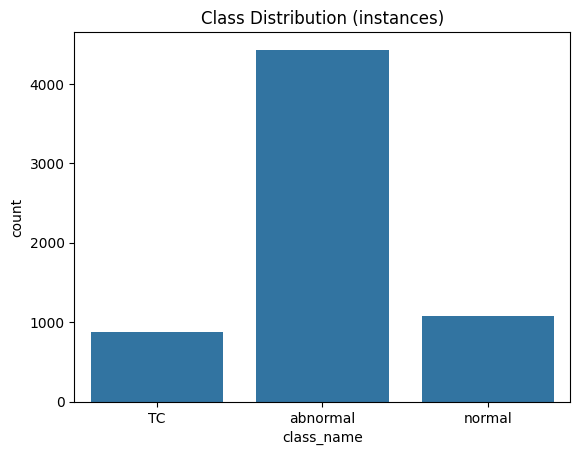

In [ ]:
# Class Distribution + Plot
columns = ['file', 'class_id', 'x_center', 'y_center', 'width', 'height']
df1 = pd.DataFrame(data, columns=columns)

print("\nClass distribution (instances):")
print((df1['class_id'].value_counts() / df1.shape[0]) * 100)

name_map = {0: 'TC', 1: 'abnormal', 2: 'normal'}
df1['class_name'] = df1['class_id'].map(name_map)

sns.countplot(x='class_name', data=df1,
              order=['TC', 'abnormal', 'normal'])
plt.title("Class Distribution (instances)")
plt.show()

In [ ]:
# Build Unique Image List + Stratified Split

# One row per unique image — dominant class for stratification
df1['file_jpg'] = df1['file'].str.replace('.txt', '.jpg')
df_unique = (
    df1.groupby('file_jpg')['class_id']
    .agg(lambda x: x.mode()[0])
    .reset_index()
    .rename(columns={'class_id': 'dominant_class'})
)

print(f"Unique images available: {len(df_unique)}")
print("\nImage count per dominant class:")
for cls_id, count in df_unique['dominant_class'].value_counts().items():
    print(f"  {cls_id} ({new_class_names[cls_id]}): {count} images")

# Stratified 70 / 15 / 15 split
train_df, temp_df = train_test_split(
    df_unique, test_size=0.3, random_state=42,
    stratify=df_unique['dominant_class']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42,
    stratify=temp_df['dominant_class']
)

print(f"\nSplit sizes:")
print(f"  Train: {len(train_df)} images")
print(f"  Val:   {len(val_df)} images")
print(f"  Test:  {len(test_df)} images")

Unique images available: 398

Image count per dominant class:
  1 (abnormal): 270 images
  2 (normal): 98 images
  0 (TC): 30 images

Split sizes:
  Train: 278 images
  Val:   60 images
  Test:  60 images


In [ ]:
# Copy Files into Final Dataset Folder
base_folder = "/content/thyroid_3class"

for split in ['train', 'val', 'test']:
    os.makedirs(f"{base_folder}/{split}/images", exist_ok=True)
    os.makedirs(f"{base_folder}/{split}/labels", exist_ok=True)

def copy_split(df, split):
    copied  = 0
    skipped = 0
    for img_file in df['file_jpg']:
        label_file = img_file.replace('.jpg', '.txt')
        img_src    = os.path.join(pool_images, img_file)
        label_src  = os.path.join(filtered_label_folder, label_file)

        if not os.path.exists(img_src) or \
           not os.path.exists(label_src):
            skipped += 1
            continue

        shutil.copy(img_src,
            f"{base_folder}/{split}/images/{img_file}")
        shutil.copy(label_src,
            f"{base_folder}/{split}/labels/{label_file}")
        copied += 1

    print(f"  {split}: {copied} copied, {skipped} skipped")

print("Copying files:")
copy_split(train_df, 'train')
copy_split(val_df,   'val')
copy_split(test_df,  'test')

# Save data.yaml
data_yaml_content = {
    'train': f'{base_folder}/train/images',
    'val':   f'{base_folder}/val/images',
    'test':  f'{base_folder}/test/images',
    'nc':    3,
    'names': new_class_names,
}

with open(f"{base_folder}/data.yaml", 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print("Saved data.yaml:")
print(f"  Classes: {new_class_names}")
print(f"  nc: 3")

Copying files:
  train: 278 copied, 0 skipped
  val: 60 copied, 0 skipped
  test: 60 copied, 0 skipped
Saved data.yaml:
  Classes: ['TC', 'abnormal', 'normal']
  nc: 3


In [ ]:
import cv2
import numpy as np
import glob
import random
import os

def create_mixed_scene_v2(tc_imgs, abnormal_imgs, normal_imgs,
                           output_img_dir, output_lbl_dir, n_scenes=600):
    os.makedirs(output_img_dir, exist_ok=True)
    os.makedirs(output_lbl_dir, exist_ok=True)

    grid_size = 3  # 3x3 grid
    patch_size = 213  # 213*3 = 639 ≈ 640
    all_pools = {0: tc_imgs, 1: abnormal_imgs, 2: normal_imgs}

    for i in range(n_scenes):
        scene_labels = []
        rows = []

        # Guarantee at least 2 TC quadrants in every scene
        n_cells = grid_size * grid_size  # 9 cells
        quadrant_classes = [0, 0]  # always 2 TC
        for _ in range(n_cells - 2):
            quadrant_classes.append(random.choice([0, 1, 2]))
        random.shuffle(quadrant_classes)

        patches_grid = []
        for pi, cls in enumerate(quadrant_classes):
            row_i = pi // grid_size
            col_i = pi %  grid_size

            img_path = random.choice(all_pools[cls])
            lbl_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')

            img = cv2.imread(img_path)
            img = cv2.resize(img, (patch_size, patch_size))
            patches_grid.append(img)

            x_off = col_i * patch_size / (grid_size * patch_size)
            y_off = row_i * patch_size / (grid_size * patch_size)

            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        bx = float(parts[1]) / grid_size + x_off
                        by = float(parts[2]) / grid_size + y_off
                        bw = float(parts[3]) / grid_size
                        bh = float(parts[4]) / grid_size
                        scene_labels.append(
                            f"{cls} {bx:.6f} {by:.6f} {bw:.6f} {bh:.6f}")

        # assemble grid
        scene_rows = []
        for r in range(grid_size):
            row_patches = patches_grid[r*grid_size:(r+1)*grid_size]
            scene_rows.append(np.hstack(row_patches))
        scene = np.vstack(scene_rows)
        scene = cv2.resize(scene, (640, 640))  # ensure exact 640x640

        out_name = f"mixed_scene_v2_{i:04d}"
        cv2.imwrite(f"{output_img_dir}/{out_name}.jpg", scene)
        with open(f"{output_lbl_dir}/{out_name}.txt", 'w') as f:
            f.write('\n'.join(scene_labels))

    print(f"Created {n_scenes} 3x3 mixed scenes")

# Gather original single-class images per class
all_orig = [f for f in glob.glob(f"{base_folder}/train/images/*.jpg")
            if 'mixed_scene' not in f]

def get_dominant_class(img_path):
    lbl_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')
    counts = Counter()
    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                counts[int(parts[0])] += 1
    return counts.most_common(1)[0][0] if counts else -1

tc_only       = [f for f in all_orig if get_dominant_class(f) == 0]
abnormal_only = [f for f in all_orig if get_dominant_class(f) == 1]
normal_only   = [f for f in all_orig if get_dominant_class(f) == 2]

print(f"TC: {len(tc_only)}, Abnormal: {len(abnormal_only)}, Normal: {len(normal_only)}")

create_mixed_scene_v2(
    tc_imgs       = tc_only,
    abnormal_imgs = abnormal_only,
    normal_imgs   = normal_only,
    output_img_dir = f"{base_folder}/train/images",
    output_lbl_dir = f"{base_folder}/train/labels",
    n_scenes       = 600
)

TC: 21, Abnormal: 189, Normal: 68
Created 600 3x3 mixed scenes


In [ ]:
def augment_patch(img):
    # random brightness
    factor = random.uniform(0.7, 1.3)
    img = np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    # random contrast
    mean = img.mean()
    factor2 = random.uniform(0.8, 1.2)
    img = np.clip((img.astype(np.float32) - mean) * factor2 + mean, 0, 255).astype(np.uint8)
    return img

def add_grid_border(scene, grid_size, patch_size, border=2):
    for i in range(1, grid_size):
        x = i * patch_size
        cv2.line(scene, (x, 0), (x, scene.shape[0]), (200,200,200), border)
        cv2.line(scene, (0, x), (scene.shape[1], x), (200,200,200), border)
    return scene

In [ ]:
from collections import Counter

all_orig = [f for f in glob.glob(f"{base_folder}/train/images/*.jpg")
            if 'mixed_scene' not in f]

def get_dominant_class(img_path):
    lbl_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')
    counts = Counter()
    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            if parts: counts[int(parts[0])] += 1
    return counts.most_common(1)[0][0] if counts else -1

tc_only       = [f for f in all_orig if get_dominant_class(f) == 0]
abnormal_only = [f for f in all_orig if get_dominant_class(f) == 1]
normal_only   = [f for f in all_orig if get_dominant_class(f) == 2]

print(f"TC: {len(tc_only)}, Abnormal: {len(abnormal_only)}, Normal: {len(normal_only)}")

create_mixed_scene_v2(
    tc_imgs        = tc_only,
    abnormal_imgs  = abnormal_only,
    normal_imgs    = normal_only,
    output_img_dir = f"{base_folder}/train/images",
    output_lbl_dir = f"{base_folder}/train/labels",
    n_scenes       = 600
)

TC: 21, Abnormal: 189, Normal: 68
Created 600 3x3 mixed scenes


In [ ]:
# Verify Final Distribution
print("\nFinal dataset distribution:")
for split in ['train', 'val', 'test']:
    lbls   = glob.glob(f"{base_folder}/{split}/labels/*.txt")
    counts = Counter()
    for lbl in lbls:
        with open(lbl) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    counts[int(parts[0])] += 1
    print(f"\n  {split}: {len(lbls)} images")
    for cls_id, name in enumerate(new_class_names):
        print(f"    {cls_id} ({name}): {counts[cls_id]} instances")



Final dataset distribution:

  train: 878 images
    0 (TC): 75901 instances
    1 (abnormal): 27238 instances
    2 (normal): 16046 instances

  val: 60 images
    0 (TC): 111 instances
    1 (abnormal): 648 instances
    2 (normal): 176 instances

  test: 60 images
    0 (TC): 149 instances
    1 (abnormal): 591 instances
    2 (normal): 158 instances


In [ ]:
import glob, os
from collections import Counter, defaultdict

label_files = glob.glob(f"{base_folder}/train/labels/*.txt")

# Count images per class (not instances)
images_per_class = defaultdict(int)
class_composition = Counter()

for lbl in label_files:
    with open(lbl) as f:
        classes_in_image = set()
        for line in f:
            parts = line.strip().split()
            if parts:
                classes_in_image.add(int(parts[0]))

    for c in classes_in_image:
        images_per_class[c] += 1

    key = tuple(sorted(classes_in_image))
    class_composition[key] += 1

print("Images containing each class:")
for cls, count in sorted(images_per_class.items()):
    print(f"  {new_class_names[cls]} ({cls}): {count}/{len(label_files)} images ({100*count/len(label_files):.1f}%)")

print("\nImage composition breakdown:")
for composition, count in class_composition.most_common():
    names = [new_class_names[c] for c in composition]
    print(f"  {names}: {count} images")

Images containing each class:
  TC (0): 621/878 images (70.7%)
  abnormal (1): 758/878 images (86.3%)
  normal (2): 638/878 images (72.7%)

Image composition breakdown:
  ['TC', 'abnormal', 'normal']: 539 images
  ['abnormal']: 189 images
  ['normal']: 68 images
  ['TC', 'normal']: 31 images
  ['TC', 'abnormal']: 30 images
  ['TC']: 21 images


In [ ]:
import glob
from collections import Counter

# Check class distribution in the new mixed scenes
mixed_labels = glob.glob(f"{base_folder}/train/labels/mixed_scene_*.txt")
print(f"Mixed scene label files: {len(mixed_labels)}")

counts = Counter()
for lbl in mixed_labels:
    with open(lbl) as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                counts[int(parts[0])] += 1

print("Class instances in mixed scenes:")
for cls, count in sorted(counts.items()):
    print(f"  {new_class_names[cls]} ({cls}): {count}")

# Check total training distribution now
all_labels = glob.glob(f"{base_folder}/train/labels/*.txt")
total_counts = Counter()
for lbl in all_labels:
    with open(lbl) as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                total_counts[int(parts[0])] += 1

print(f"\nTotal training instances (original + mixed):")
for cls, count in sorted(total_counts.items()):
    print(f"  {new_class_names[cls]} ({cls}): {count}")
print(f"Total training images: {len(all_labels)}")

Mixed scene label files: 600
Class instances in mixed scenes:
  TC (0): 75287
  abnormal (1): 24048
  normal (2): 15300

Total training instances (original + mixed):
  TC (0): 75901
  abnormal (1): 27238
  normal (2): 16046
Total training images: 878


In [ ]:
total = glob.glob(f"{base_folder}/train/images/*.jpg")
mixed = [f for f in total if 'mixed_scene' in f]
print(f"Original: {len(total)-len(mixed)}, Mixed: {len(mixed)}, Total: {len(total)}")

Original: 278, Mixed: 600, Total: 878


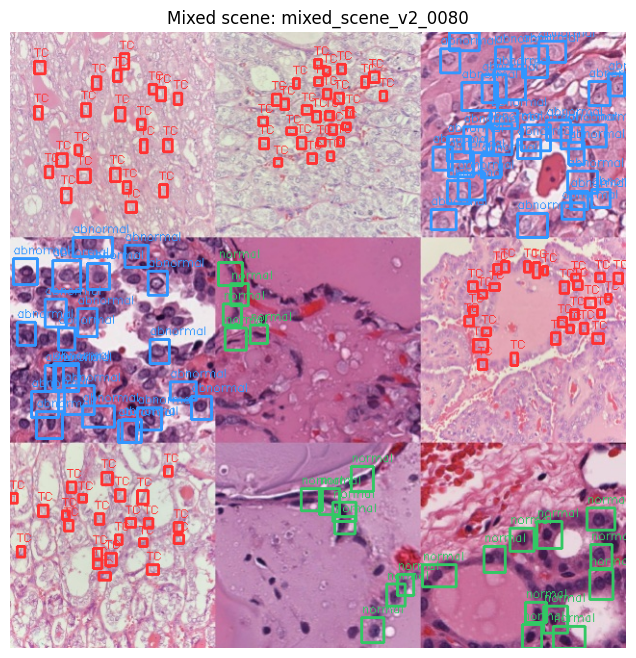

In [ ]:
import cv2
import matplotlib.pyplot as plt
import random, glob

mixed_imgs = glob.glob(f"{base_folder}/train/images/mixed_scene_*.jpg")
sample = random.choice(mixed_imgs)
stem   = os.path.splitext(os.path.basename(sample))[0]
lbl    = f"{base_folder}/train/labels/{stem}.txt"

img = cv2.imread(sample)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

colors = {0: (255,50,50), 1: (50,150,255), 2: (50,200,100)}

with open(lbl) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) == 5:
            cls = int(parts[0])
            bx, by, bw, bh = map(float, parts[1:])
            x1 = int((bx - bw/2) * w)
            y1 = int((by - bh/2) * h)
            x2 = int((bx + bw/2) * w)
            y2 = int((by + bh/2) * h)
            cv2.rectangle(img, (x1,y1), (x2,y2), colors[cls], 2)
            cv2.putText(img, new_class_names[cls], (x1, y1-5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.4, colors[cls], 1)

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.title(f"Mixed scene: {stem}")
plt.axis('off')
plt.show()

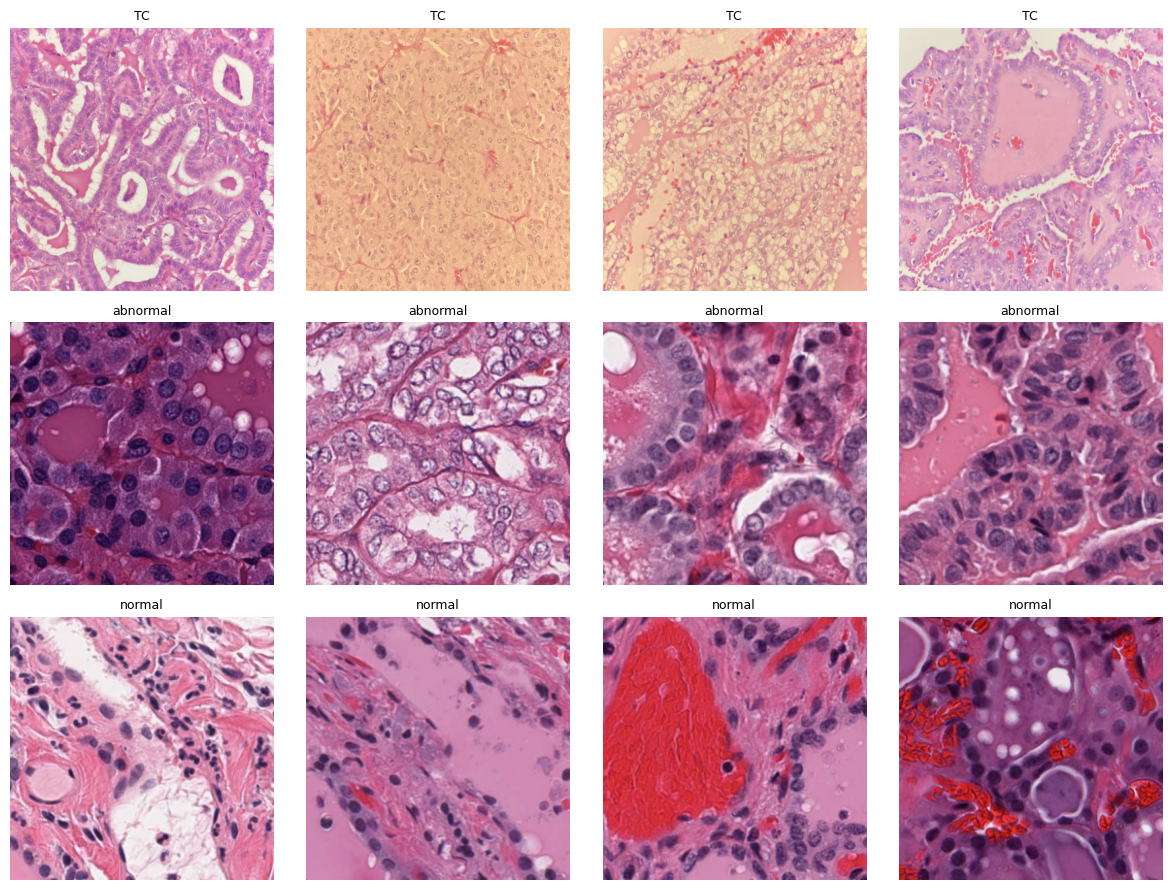

In [ ]:
from PIL import Image
import glob, random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, (cls, name) in enumerate([(0,'TC'), (1,'abnormal'), (2,'normal')]):
    # get original single-class images for this class
    cls_imgs = []
    for img_path in glob.glob(f"{base_folder}/train/images/*.jpg"):
        if 'mixed_scene' in img_path:
            continue
        lbl = img_path.replace('/images/','/labels/').replace('.jpg','.txt')
        with open(lbl) as f:
            classes = {int(l.split()[0]) for l in f if l.strip()}
        if classes == {cls}:
            cls_imgs.append(img_path)

    samples = random.sample(cls_imgs, min(4, len(cls_imgs)))
    for col, img_path in enumerate(samples):
        img = Image.open(img_path)
        axes[row][col].imshow(img)
        axes[row][col].set_title(name, fontsize=9)
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model = YOLO("yolo26s-cls.pt")

model.train(
    data=f"{base_folder}/data.yaml",
    epochs=100,        # increased — more mixed scenes need more epochs
    imgsz=640,
    batch=16,
    device=0,
    optimizer="AdamW",
    cos_lr=True,
    patience=0,
    # Tuned hyperparameters
    lr0=0.0001,
    lrf=0.01,
    warmup_epochs=10,
    mosaic=0.0,        # TURN OFF — you already have mixed scenes, mosaic on top creates chaotic compositions
    degrees=90.0,      # add rotation since histopathology has no orientation
    # class imbalance weights
    cls=3.0,
    box=7.5,
    # Augmentations
    flipud=0.5,
    fliplr=0.5,
    hsv_h=0.01,
    hsv_s=0.3,         # lowered from 0.5 — H&E stain colors are diagnostically important
    hsv_v=0.3,
    copy_paste=0.0,
    label_smoothing=0.1,
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=3.0, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/thyroid_3class/data.yaml, degrees=90.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-cls.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=train, nbs=64, nm

RuntimeError: Dataset '/content/thyroid_3class/data.yaml' error ❌ Classification datasets must be a directory (data="path/to/dir") not a file (data="/content/thyroid_3class/data.yaml"), See https://docs.ultralytics.com/datasets/classify/

In [ ]:
model = YOLO(f"/content/runs/detect/trainX/weights/best.pt")
model.val(
    data=f"{base_folder}/data.yaml",
    split="test",   # runs on test set instead of val
    conf=0.1,
)